# Semana 7: Puntos fijos, estabilidad y retratos de fase

**Objetivo:** clasificar un punto fijo a partir de los autovalores de la matriz del sistema y
reconocer esa clasificación en el retrato de fase.

## Modelo

Sistema lineal en dos dimensiones, con punto fijo en el origen:

$$\dot{\mathbf{x}} = A\,\mathbf{x}, \qquad \mathbf{x}(t) = V\, e^{\Lambda t}\, V^{-1}\, \mathbf{x}(0)$$

donde $A = V \Lambda V^{-1}$ es la descomposición en autovalores $\lambda_i$. La estabilidad
depende solo de los $\lambda_i$:

| Autovalores | Tipo de punto fijo |
|---|---|
| complejos, $\text{Re}\,\lambda < 0$ | foco estable (espiral hacia dentro) |
| reales, signos opuestos ($\det A < 0$) | silla (inestable) |
| reales, ambos negativos | nodo estable |

Se comparan dos matrices:

$$A_\text{foco} = \begin{pmatrix} -1 & -2 \\ 2 & -1 \end{pmatrix}, \qquad
  A_\text{silla} = \begin{pmatrix} 0.2 & 1 \\ 1 & -0.6 \end{pmatrix}$$

Las trayectorias se calculan con la solución exacta, no con Euler, para que el retrato no tenga
error numérico.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience.outputs import save_data, save_figure

WEEK = 7
systems = {
    "Stable focus": np.array([[-1.0, -2.0], [2.0, -1.0]]),
    "Saddle": np.array([[0.2, 1.0], [1.0, -0.6]]),
}
initial_states = [np.array(point) for point in ((2.0, 0.0), (0.0, 2.0), (-2.0, 1.0), (1.0, -2.0))]


def exact_trajectory(matrix: np.ndarray, initial: np.ndarray, time: np.ndarray) -> np.ndarray:
    eigenvalues, eigenvectors = np.linalg.eig(matrix)
    coefficients = np.linalg.solve(eigenvectors, initial)
    states = (eigenvectors @ (coefficients[:, None] * np.exp(eigenvalues[:, None] * time[None, :]))).T
    return states.real


def classify(matrix: np.ndarray) -> str:
    eigenvalues = np.linalg.eigvals(matrix)
    if np.linalg.det(matrix) < 0:
        return "saddle"
    if np.all(eigenvalues.real < 0):
        return "stable focus" if np.any(np.abs(eigenvalues.imag) > 1e-12) else "stable node"
    return "unstable"

## Figura

Fondo: campo vectorial $A\mathbf{x}$. Líneas de color: trayectorias desde cuatro condiciones
iniciales (círculos). En la silla, las líneas discontinuas son los autovectores: la dirección
estable (atrae) y la inestable (repele).

Saved: weeks/week_07_fixed_points/outputs/fixed_point_trajectories.png
Saved: weeks/week_07_fixed_points/outputs/linear_system.npz


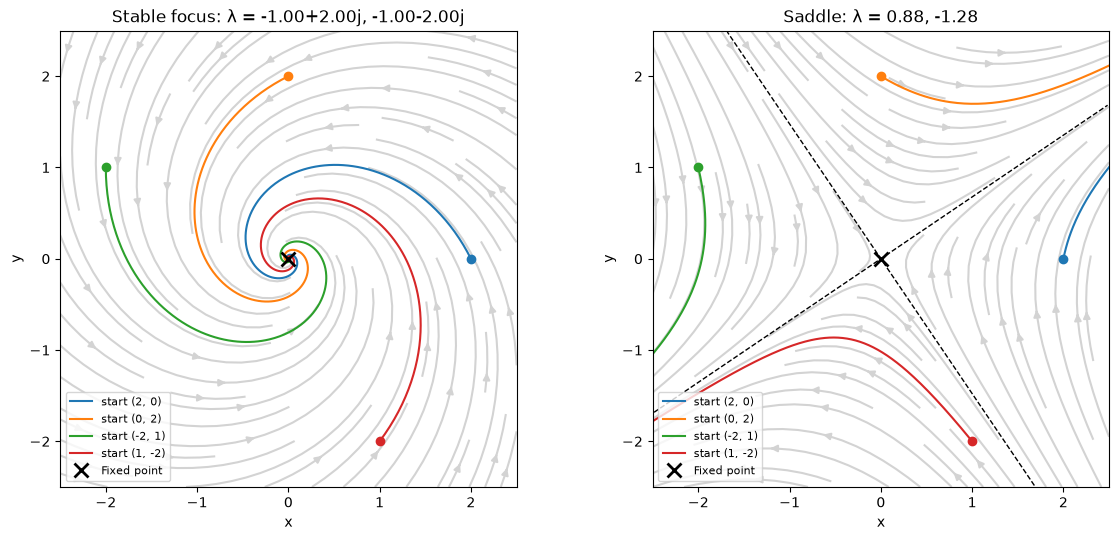

In [2]:
time = np.linspace(0.0, 6.0, 600)
grid = np.linspace(-2.5, 2.5, 25)
grid_x, grid_y = np.meshgrid(grid, grid)
figure, axes = plt.subplots(1, 2, figsize=(12, 5.5))
saved = {}
for axis, (name, matrix) in zip(axes, systems.items()):
    flow = np.einsum("ij,jkl->ikl", matrix, np.stack((grid_x, grid_y)))
    axis.streamplot(grid_x, grid_y, flow[0], flow[1], color="lightgrey", density=1.0)
    for initial in initial_states:
        states = exact_trajectory(matrix, initial, time)
        line, = axis.plot(states[:, 0], states[:, 1], label=f"start ({initial[0]:g}, {initial[1]:g})")
        axis.plot(*initial, "o", color=line.get_color())
    eigenvalues, eigenvectors = np.linalg.eig(matrix)
    if name == "Saddle":
        for value, vector in zip(eigenvalues.real, eigenvectors.T.real):
            axis.plot(*(np.outer([-3, 3], vector).T), "k--", linewidth=1)
    axis.plot(0.0, 0.0, "kx", markersize=10, mew=2, label="Fixed point")
    eigen_text = ", ".join(f"{value:.2f}" for value in np.round(eigenvalues, 2))
    axis.set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), xlabel="x", ylabel="y", aspect="equal",
             title=f"{name}: λ = {eigen_text}")
    axis.legend(fontsize=8, loc="lower left")
    saved[f"{name.lower().replace(' ', '_')}_matrix"] = matrix
    saved[f"{name.lower().replace(' ', '_')}_eigenvalues"] = eigenvalues
save_figure(WEEK, figure, "fixed_point_trajectories.png")
save_data(WEEK, "linear_system.npz", **saved)

## Validación

- La solución exacta cumple $\dot{\mathbf{x}} = A\mathbf{x}$ (derivada numérica).
- El foco tiene autovalores $-1 \pm 2i$ y todas sus trayectorias terminan cerca del origen.
- La silla tiene $\det A < 0$ y casi todas sus trayectorias se alejan del origen.

In [3]:
for name, matrix in systems.items():
    states = exact_trajectory(matrix, initial_states[0], time)
    derivative = np.gradient(states, time, axis=0)
    assert np.allclose(derivative[5:-5], states[5:-5] @ matrix.T, atol=1e-2), name
assert classify(systems["Stable focus"]) == "stable focus"
assert np.allclose(np.sort_complex(np.linalg.eigvals(systems["Stable focus"])), [-1 - 2j, -1 + 2j])
assert all(np.linalg.norm(exact_trajectory(systems["Stable focus"], x0, time)[-1]) < 0.01 for x0 in initial_states)
assert classify(systems["Saddle"]) == "saddle"
assert all(np.linalg.norm(exact_trajectory(systems["Saddle"], x0, time)[-1]) > 2.5 for x0 in initial_states)
for name, matrix in systems.items():
    print(f"{name}: eigenvalues {np.round(np.linalg.eigvals(matrix), 3)}, class = {classify(matrix)}")

Stable focus: eigenvalues [-1.+2.j -1.-2.j], class = stable focus
Saddle: eigenvalues [ 0.877 -1.277], class = saddle


## Interpretación y límites

- La parte imaginaria de $\lambda$ fija la frecuencia de giro ($|\text{Im}\,\lambda| = 2$ rad por
  unidad de tiempo) y la parte real la velocidad de convergencia o divergencia.
- En sistemas no lineales (HH, Wilson-Cowan) se aplica el mismo análisis a la **linealización**
  (jacobiano) alrededor de cada punto fijo; solo es válido localmente.

**Para tu entrega:** encuentra una matriz con un nodo estable y otra con un foco inestable, y
anota sus autovalores antes de graficarlas.